In [1]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from backpac.systems.generic import MPLCSystem
from backpac.utils.costs import loss_WFM, loss_nuisance_crosstalk
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom
from backpac.apply_complex_map import apply_complex_map
from backpac.utils.operations import apply_random_shifts

In [2]:
#Define MPLC parameters
aperture_diameter = 9e-3  # Aperture diameter
mplc_diameter = 12e-3  # MPLC diameter
oversizing = mplc_diameter / aperture_diameter  # Oversizing factor for the simulation
simulation_diameter = aperture_diameter * oversizing  # Simulation diameter
num_planes = 4  # Number of phase screens
total_length = 30.0e-2 # Initial total length of the system
center_wavel = 632e-9  # Center wavelength for the system
wavelength_min = center_wavel * 0.995  # Minimum wavelength for the system
wavelength_max = center_wavel * 1.005  # Maximum wavelength for the system

2400
5e-06


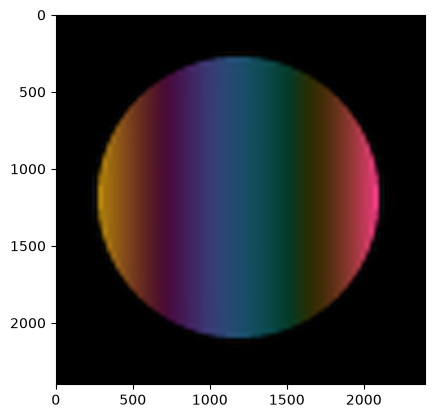

In [3]:
#Load input mode
input_mode = np.load('demos/mplc_input_single_mode.npy') #relative to workspace root

#zero pad the input mode so its array size scales by factor of oversizing (supports non-integer oversizing)
target_shape = [int(round(s * oversizing)) for s in input_mode.shape]
pad_widths = [((t - s) // 2, t - s - (t - s) // 2) for s, t in zip(input_mode.shape, target_shape)]
input_mode = np.pad(input_mode, pad_widths, mode='constant')

bin_size = 2  # Binning factor for the simulation

lc_pix_size = 10e-6  # Liquid crystal pixel size
simulation_pix_size = lc_pix_size / bin_size  # Simulation pixel size
wf_npixels = round(simulation_diameter / simulation_pix_size)  # Number of pixels in the simulation

print(wf_npixels)
print(simulation_pix_size)

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

#interpolate input mode to match wf_npixels using zoom
input_mode = zoom(input_mode, (wf_npixels / input_mode.shape[0], wf_npixels / input_mode.shape[1]), order=3)

#re-normalize since zoom's resampling changes the sum of squared magnitudes
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

plt.figure()
plt.imshow(apply_complex_map(input_mode))

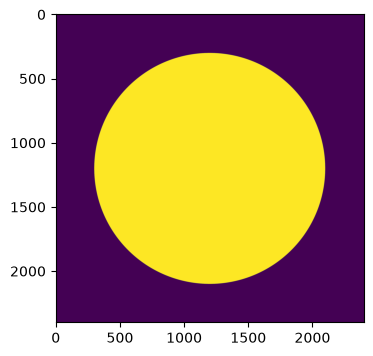

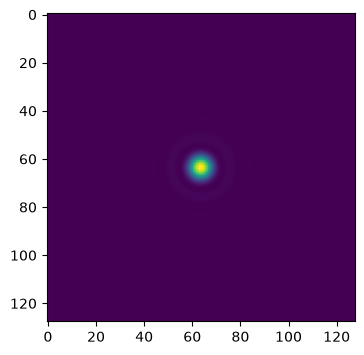

In [4]:
#Calculate output mode
focal_length = total_length # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront

zernike_nolls = np.array(np.arange(1, 11))  # Zernike Noll indices for basis generation
circ_aper, telescope_modes = dlu.circular_aperture(npixels=wf_npix, diameter = aperture_diameter, oversample=5, array_diameter=simulation_diameter, zernike_nolls=zernike_nolls)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 128  # Number of pixels in the PSF plane
psf_pixel_scale = aperture_diameter / wf_npix # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=aperture_diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

plt.figure(figsize=(15, 4))
plt.imshow(circ_aper)

plt.figure(figsize=(15, 4))
plt.imshow(np.abs(output_mode)**2)

In [5]:
mplc_system = MPLCSystem(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    aperture_diameter = aperture_diameter,
    mplc_diameter = mplc_diameter,
    array_diameter = simulation_diameter,
    bin_size = bin_size,
    num_planes = num_planes,
    total_length = total_length,
    target_coordspec_n =psf_npix,
    target_coordspec_d = psf_pixel_scale,
    wavelengths = np.array([center_wavel]),
    telescope_modes = telescope_modes)

nuisance_modes = mplc_system.calculate_nuisance_modes(n_nuisance=5)

In [6]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc_system.wf_npixels, mplc_system.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc_system.wf_npixels, mplc_system.wf_npixels))

In [10]:
#Loss function with random misalignment and random wavelength and random total_length perturbation and nuisance crosstalk term
def _chunk_loss(params, mplc_system, nuisance_modes, chunk_keys, sigma_pix, sigma_length, wavelength_min, wavelength_max, crosstalk_weight):
    def perturb_system(sample_key):
        key_shift, key_temp = jax.random.split(sample_key)
        key_wavel, key_length = jax.random.split(key_temp)
        sample_params = dict(params)
        sample_params['phase_screens'] = apply_random_shifts(params['phase_screens'], key_shift, sigma_pix)
        sample_params['total_length'] = params['total_length'] + sigma_length * jax.random.normal(key_length, shape=())
        sample_system = mplc_system.with_params(sample_params)
        random_wavelength = jax.random.uniform(key_wavel, minval=wavelength_min, maxval=wavelength_max)
        return sample_system.set("wavelengths", np.array([random_wavelength]))

    if nuisance_modes is None:
        res = eqx.filter_vmap(lambda k: perturb_system(k)())(chunk_keys)
        return loss_WFM(res, mplc_system.target_modes)
    else:
        def propagate_one(sample_key):
            sample_system = perturb_system(sample_key)
            return sample_system(), sample_system.propagate_modes(nuisance_modes)

        res, res_nuisance = eqx.filter_vmap(propagate_one)(chunk_keys)
        return loss_WFM(res, mplc_system.target_modes) + crosstalk_weight * loss_nuisance_crosstalk(res, res_nuisance, mplc_system.target_modes)


@eqx.filter_jit
def loss_fn_combined_crosstalk(params, mplc_system, nuisance_modes, key, n_batch = 8, micro_batch_size = None, sigma_pix = 1.0, sigma_length = 1e-3, wavelength_min = wavelength_min, wavelength_max = wavelength_max, crosstalk_weight = 0.1):
    # Mini-batch + gradient accumulation: bounds peak memory to micro_batch_size instead of n_batch.
    # micro_batch_size=None (default) replicates the old single-vmap behaviour (one chunk of size n_batch).
    micro_batch_size = n_batch if micro_batch_size is None else micro_batch_size
    assert n_batch % micro_batch_size == 0, "n_batch must be divisible by micro_batch_size"
    n_micro_batches = n_batch // micro_batch_size

    keys = jax.random.split(key, n_batch).reshape(n_micro_batches, micro_batch_size, -1)

    chunk_value_and_grad = eqx.filter_value_and_grad(
        lambda p, chunk_keys: _chunk_loss(
            p, mplc_system, nuisance_modes, chunk_keys, sigma_pix, sigma_length,
            wavelength_min, wavelength_max, crosstalk_weight,
        )
    )

    def scan_body(carry, chunk_keys):
        loss_acc, grad_acc = carry
        loss_val, grad_val = chunk_value_and_grad(params, chunk_keys)
        grad_acc = jax.tree_util.tree_map(lambda a, b: a + b, grad_acc, grad_val)
        return (loss_acc + loss_val, grad_acc), None

    # scan processes chunks sequentially so XLA can reuse buffers between iterations, unlike a single large vmap
    zero_grad = jax.tree_util.tree_map(np.zeros_like, params)
    (total_loss, total_grad), _ = jax.lax.scan(scan_body, (0.0, zero_grad), keys)

    mean_grad = jax.tree_util.tree_map(lambda g: g / n_micro_batches, total_grad)
    return total_loss / n_micro_batches, mean_grad


In [11]:
params = {
    "phase_screens": initial_phase_screens,
    "total_length": np.array(total_length),
}

optimizers = {
    "phase_screens": optax.adam(learning_rate=1e-2),
    "total_length": optax.adam(learning_rate=1e-3),
}
optim, opt_state = zdx.map_optimisers(params, optimizers)

key = jax.random.PRNGKey(0)

sigma_pix = 2.0  # Standard deviation for random misalignment in pixels
sigma_length = 1e-3  # Standard deviation for random total length perturbation in meters
n_batch = 16  # Number of independent samples for Monte Carlo estimation
micro_batch_size = 2  # Size of each micro-batch for gradient accumulation

#test the loss function
initial_loss, initial_grad = loss_fn_combined_crosstalk(params, mplc_system, None, key, n_batch=2, sigma_pix = sigma_pix, sigma_length = sigma_length, wavelength_min = wavelength_min, wavelength_max = wavelength_max)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

initial_crosstalk = loss_nuisance_crosstalk(mplc_system()[None], mplc_system.propagate_modes(nuisance_modes)[None], mplc_system.target_modes)
print("Initial crosstalk:", initial_crosstalk)

Initial loss: 0.99998224
Initial gradient norm: 0.00024564558
Initial crosstalk: 0.4346864


In [13]:
# Run the optimisation loop without crosstalk term
losses, params_out = [], []
num_iters = 1000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        key, subkey = jax.random.split(key)  # fresh randomness each iteration
        loss, grads = loss_fn_combined_crosstalk(params, mplc_system, None, subkey, n_batch=n_batch, micro_batch_size=micro_batch_size, sigma_pix = sigma_pix, sigma_length = sigma_length, wavelength_min = wavelength_min, wavelength_max = wavelength_max)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/1000 [00:00<?, ?it/s]

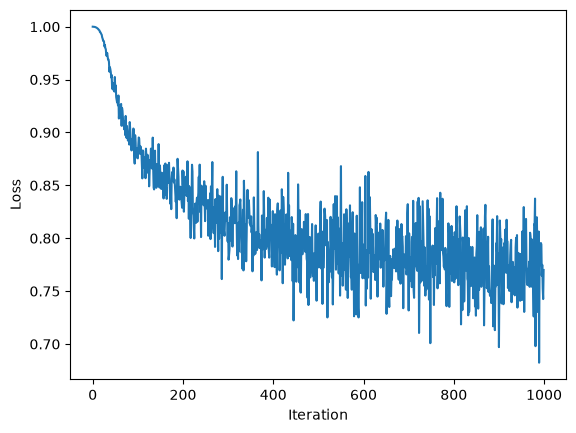

In [14]:
plt.figure()
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

In [15]:
# phase_screens_loaded = np.load('demos/results/30cm/temporary_before_crosstalk.npy')
# params['phase_screens'] = phase_screens_loaded

mplc_system = mplc_system.with_params(params)
crosstalk_current = loss_nuisance_crosstalk(mplc_system()[None], mplc_system.propagate_modes(nuisance_modes)[None], mplc_system.target_modes)
print(crosstalk_current)

np.save('demos/results/30cm/temporary_before_crosstalk.npy', params['phase_screens'])

-0.82367176


In [17]:
# Run the optimisation loop with a crosstalk term

crosstalk_weight = 0.1

losses, params_out = [], []
num_iters = 100
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        key, subkey = jax.random.split(key)  # fresh randomness each iteration
        loss, grads = loss_fn_combined_crosstalk(params, mplc_system, nuisance_modes, subkey, n_batch=n_batch, micro_batch_size=micro_batch_size, sigma_pix = sigma_pix, sigma_length = sigma_length, wavelength_min = wavelength_min, wavelength_max = wavelength_max, crosstalk_weight = crosstalk_weight)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/100 [00:00<?, ?it/s]

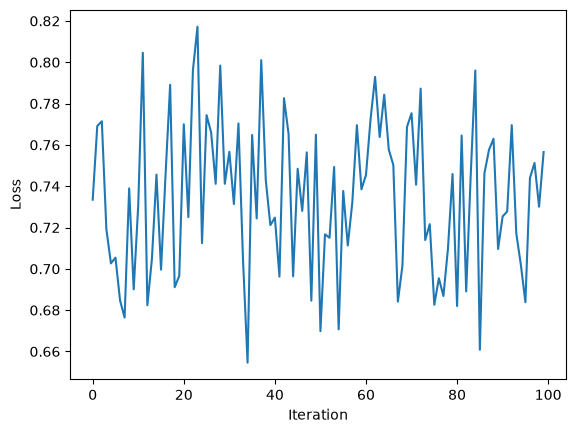

In [18]:
plt.figure()
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

0.30222467
Final fidelity: 0.44303846
Final log10 crosstalk: -1.170462


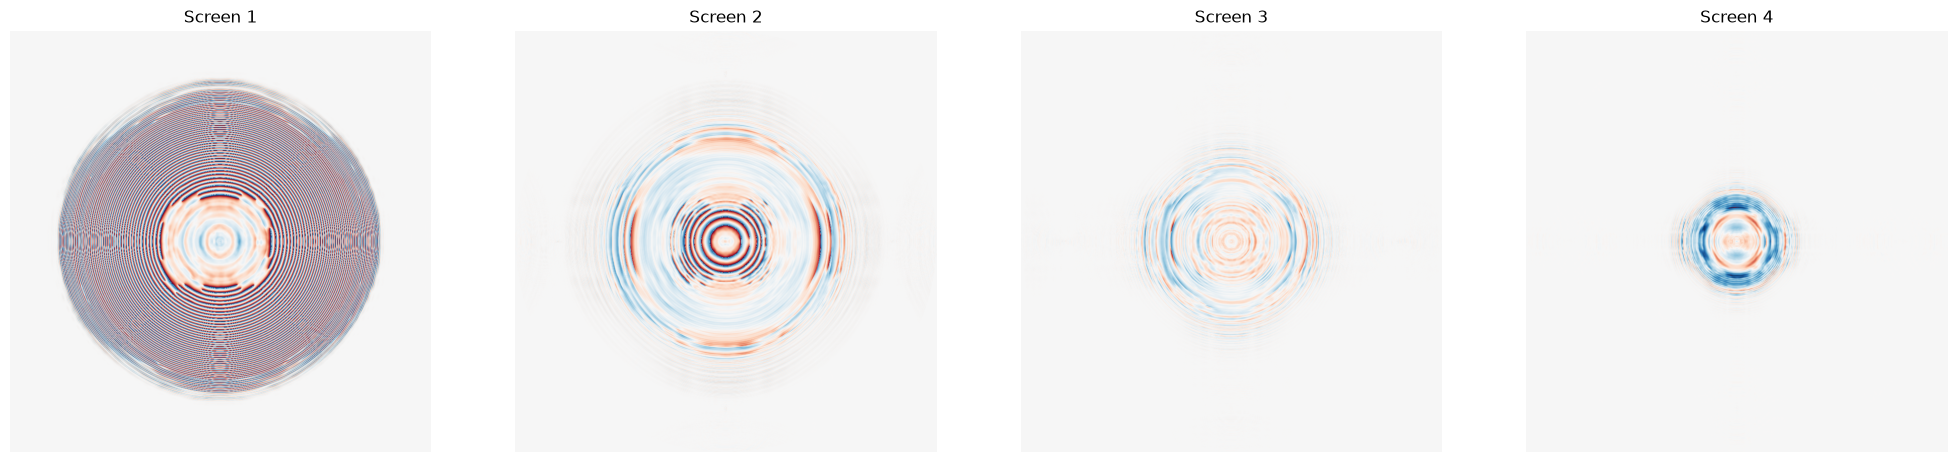

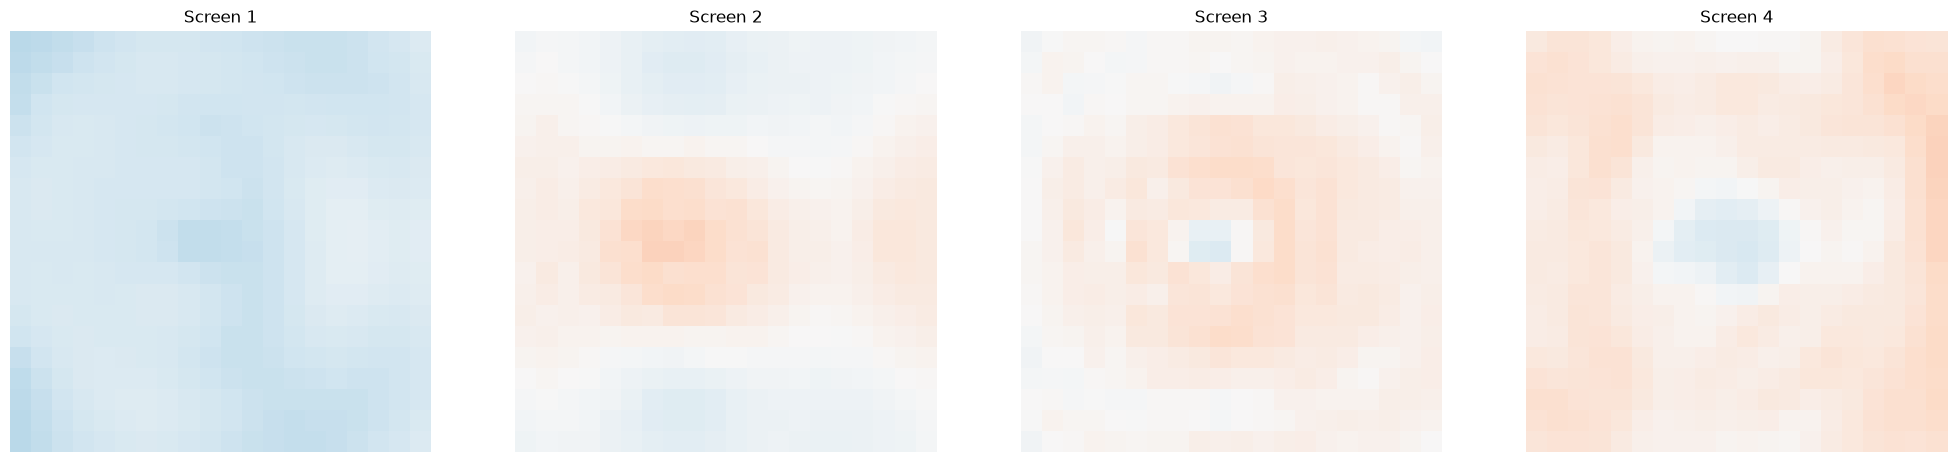

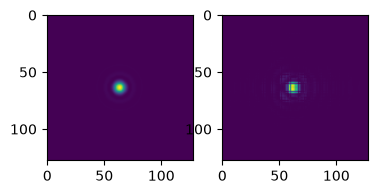

In [19]:
#plot the final phase screens

mplc_system_final = mplc_system.with_params(params)
filtered_phase_screens_final = mplc_system_final.mplc.phase_screens

np.save('demos/results/30cm/phase_screens_bandwidth01random_jitter10um_lengthjitter1e-3_crosstalk0p1.npy', filtered_phase_screens_final)

#wrap phase screens between -pi and pi
wrapped_phase_screens_final = np.mod(filtered_phase_screens_final + np.pi, 2 * np.pi) - np.pi

cmap = 'RdBu'

plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i], cmap=cmap, vmin=-np.pi, vmax=np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#plot the center 20 pixels of the final phase screens
crop = 20
center = filtered_phase_screens_final.shape[-1] // 2
plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i][center-crop:center+crop, center-crop:center+crop], cmap=cmap, vmin=-np.pi, vmax=np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc_system_final()

print(params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)

#Final fidelity and crosstalk
final_fidelity = 1-loss_WFM(res_final[None], mplc_system_final.target_modes)
final_crosstalk = loss_nuisance_crosstalk(res_final[None], mplc_system_final.propagate_modes(nuisance_modes)[None], mplc_system_final.target_modes)
print("Final fidelity:", final_fidelity)
print("Final log10 crosstalk:", final_crosstalk)